# NYC Taxi Trips — March 2019

**Questions**
1. When do New Yorkers take taxis, and how does traffic change the ride?
2. How is a fare built — what does distance actually cost?
3. Who tips, and how much?

**Data:** 6,433 yellow and green cab trips from the NYC Taxi & Limousine Commission (TLC) trip records, March 2019 (sample distributed with the seaborn example datasets). One row per trip: timestamps, passengers, distance, fare, tip, tolls, total, cab colour, payment type and pickup/dropoff zone & borough.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

sys.path.append(str(Path.cwd().parent / "src"))
import taxi
from plotting import set_style, save, BLUE, ORANGE, AQUA, TEXT_SECONDARY, SEQUENTIAL

set_style()
pd.set_option("display.precision", 2)

## 1. Load and clean

In [2]:
raw = taxi.load_raw()
print(f"{len(raw):,} raw trips, {raw.shape[1]} columns")
raw.isna().sum()[lambda s: s > 0]

6,433 raw trips, 14 columns


payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

A handful of trips have no payment type or zone; they are kept (they're still valid trips) and simply drop out of the analyses that need those fields. Rows that can't be real trips are removed:

In [3]:
df, removal_log = taxi.clean(raw)
df.to_csv(taxi.PROCESSED_PATH, index=False)
print(f"{len(df):,} trips kept ({len(raw) - len(df)} removed)")
removal_log

6,348 trips kept (85 removed)


,rule,rows_removed
0,pickup outside March 2019,1
1,zero distance,51
2,duration under 1 min or over 3 h,32
3,non-positive fare,0
4,implausible speed (> 70 mph),1


In [4]:
df[["distance", "duration_min", "speed_mph", "fare", "tip", "total", "passengers"]].describe().T

,count,mean,std,min,25%,50%,75%,max
distance,6348.0,3.06,3.84,0.09,1.00,1.67,3.25,36.70
duration_min,6348.0,14.52,11.60,1.00,6.67,11.00,18.60,107.67
speed_mph,6348.0,11.48,5.86,1.22,7.61,10.07,13.70,54.17
fare,6348.0,13.04,11.23,1.00,6.50,9.50,15.00,150.00
tip,6348.0,1.98,2.37,0.00,0.00,1.75,2.82,23.19
total,6348.0,18.49,13.42,1.30,10.80,14.16,20.30,174.82
passengers,6348.0,1.54,1.21,0.00,1.00,1.00,2.00,6.00


## 2. When do people ride?

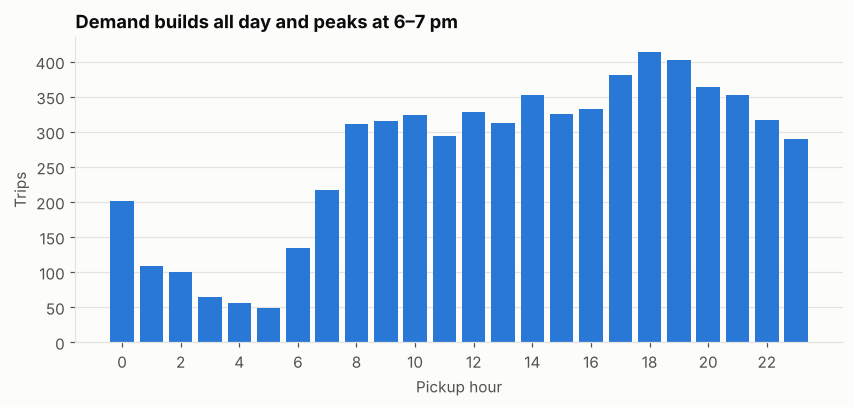

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
by_hour = df.groupby("hour").size()
ax.bar(by_hour.index, by_hour.values, color=BLUE, width=0.8)
ax.set(xlabel="Pickup hour", ylabel="Trips", xticks=range(0, 24, 2))
ax.grid(axis="x", visible=False)
ax.set_title("Demand builds all day and peaks at 6–7 pm")
save(fig, "01_trips_by_hour");

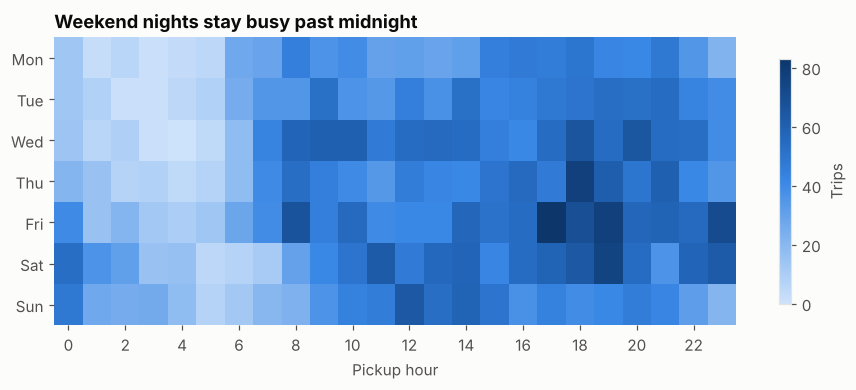

In [6]:
heat = (df.pivot_table(index="day_of_week", columns="hour", values="fare", aggfunc="size", observed=False)
          .fillna(0))
fig, ax = plt.subplots(figsize=(10, 3.4))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("blues", SEQUENTIAL)
im = ax.imshow(heat.values, aspect="auto", cmap=cmap)
ax.set(yticks=range(7), yticklabels=[d[:3] for d in heat.index],
       xticks=range(0, 24, 2), xlabel="Pickup hour")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, label="Trips", shrink=0.85)
ax.set_title("Weekend nights stay busy past midnight")
save(fig, "02_trips_day_hour_heatmap");

In [7]:
late = df[df.hour.isin([0, 1, 2, 3])]
print("Share of 0-4 am trips on Sat/Sun:", f"{late.is_weekend.mean():.0%}",
      "| share of all trips on Sat/Sun:", f"{df.is_weekend.mean():.0%}")

Share of 0-4 am trips on Sat/Sun: 55% | share of all trips on Sat/Sun: 30%


min        8.7
idxmin    16.0
max       17.3
idxmax     5.0
Name: speed_mph, dtype: float64


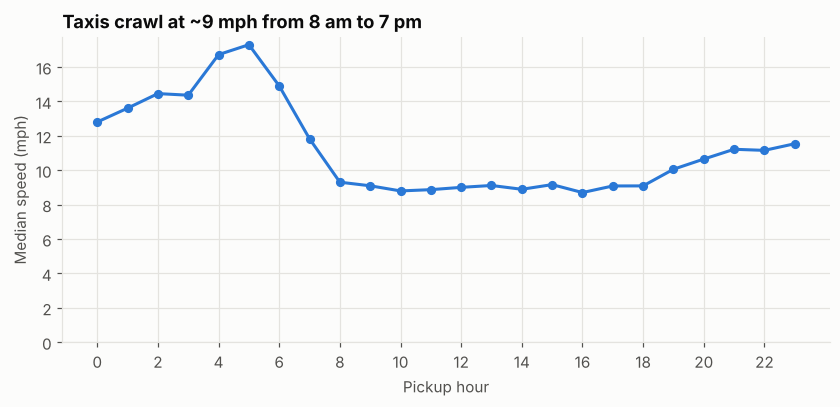

In [8]:
speed = df.groupby("hour")["speed_mph"].median()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(speed.index, speed.values, color=BLUE, marker="o", markersize=5)
ax.set(xlabel="Pickup hour", ylabel="Median speed (mph)", xticks=range(0, 24, 2), ylim=(0, None))
ax.set_title("Taxis crawl at ~9 mph from 8 am to 7 pm")
save(fig, "03_speed_by_hour");
print(speed.round(1).agg(["min", "idxmin", "max", "idxmax"]))

## 3. What does a ride cost?

Pearson r (distance, fare): 0.96


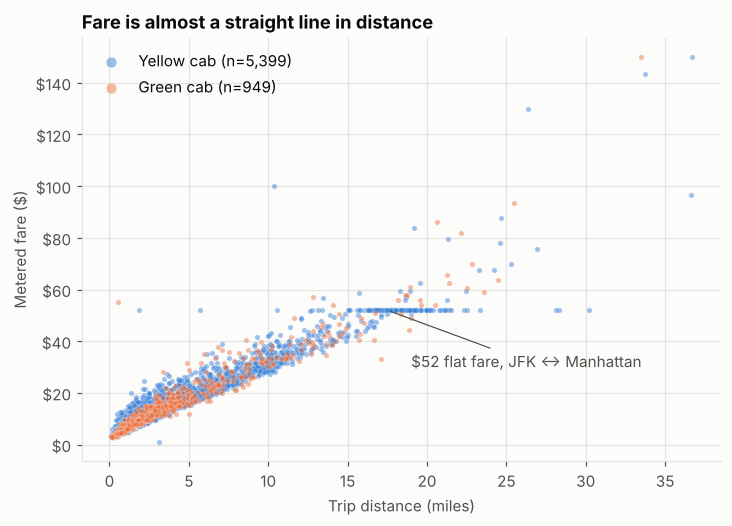

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for color, c in [("yellow", BLUE), ("green", ORANGE)]:
    sub = df[df.color == color]
    ax.scatter(sub.distance, sub.fare, s=12, alpha=0.45, color=c,
               edgecolor="white", linewidth=0.3, label=f"{color.title()} cab (n={len(sub):,})")
ax.set(xlabel="Trip distance (miles)", ylabel="Metered fare ($)")
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.legend(loc="upper left", markerscale=2)
ax.annotate("$52 flat fare, JFK ↔ Manhattan", xy=(17.5, 52), xytext=(19, 30),
            color=TEXT_SECONDARY, arrowprops=dict(arrowstyle="-", color=TEXT_SECONDARY, lw=0.8))
ax.set_title("Fare is almost a straight line in distance")
save(fig, "04_fare_vs_distance");
print("Pearson r (distance, fare):", round(df.distance.corr(df.fare), 3))

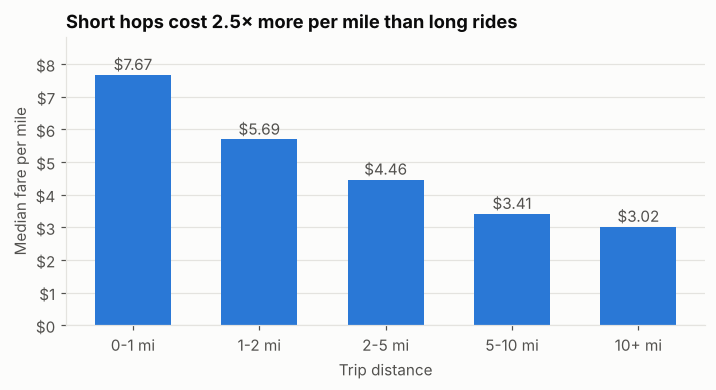

In [10]:
per_mile = df.groupby("distance_band", observed=True)["fare_per_mile"].median()
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(per_mile.index.astype(str), per_mile.values, color=BLUE, width=0.6)
for x, v in enumerate(per_mile.values):
    ax.text(x, v + 0.15, f"${v:.2f}", ha="center", color=TEXT_SECONDARY)
ax.set(xlabel="Trip distance", ylabel="Median fare per mile", ylim=(0, per_mile.max() * 1.15))
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.grid(axis="x", visible=False)
ax.set_title("Short hops cost 2.5× more per mile than long rides")
save(fig, "05_fare_per_mile");

The flag-drop charge ($2.50 in 2019) is spread over fewer miles on short trips, and time spent stuck in traffic is billed on top of distance.
A simple linear model makes that explicit — fare as a function of distance **and** time:

In [11]:
X, y = df[["distance", "duration_min"]], df["fare"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42)
model = LinearRegression().fit(X_tr, y_tr)
pred = model.predict(X_te)
print(f"fare ≈ ${model.intercept_:.2f} + ${model.coef_[0]:.2f}/mile + ${model.coef_[1]:.2f}/minute")
print(f"Test R² = {r2_score(y_te, pred):.3f}, MAE = ${mean_absolute_error(y_te, pred):.2f}")

dist_only = LinearRegression().fit(X_tr[["distance"]], y_tr)
print(f"Distance-only R² = {r2_score(y_te, dist_only.predict(X_te[['distance']])):.3f}")

fare ≈ $2.39 + $2.07/mile + $0.30/minute
Test R² = 0.972, MAE = $0.67
Distance-only R² = 0.946


In [12]:
airport = df.groupby("is_airport").agg(trips=("fare", "size"), median_distance=("distance", "median"),
                                       median_total=("total", "median"))
airport.index = ["Other trips", "Airport (JFK / LGA)"]
display(airport)
jfk_flat = df[(df.fare == 52) & (df.color == "yellow")]
print(f"{len(jfk_flat)} yellow-cab trips charged exactly $52 — the JFK↔Manhattan flat fare; "
      f"{jfk_flat.pickup_zone.eq('JFK Airport').mean() + jfk_flat.dropoff_zone.eq('JFK Airport').mean():.0%} touch JFK")

,trips,median_distance,median_total
Other trips,5948,1.56,13.8
Airport (JFK / LGA),400,10.89,50.3


125 yellow-cab trips charged exactly $52 — the JFK↔Manhattan flat fare; 92% touch JFK


## 4. Who tips?

TLC data only records tips paid by card — **every cash trip shows a $0 tip** — so tipping is analysed on card trips only.

In [13]:
print(df.groupby("payment")["tip"].agg(["count", "mean", lambda s: (s > 0).mean()])
        .rename(columns={"<lambda_0>": "share_with_tip"}))
card = df[df.payment == "credit card"]
print(f"\nCard trips: median tip = {card.tip_pct.median():.1f}% of fare, "
      f"{(card.tip == 0).mean():.0%} leave no tip")

             count  mean  share_with_tip
payment                                 
cash          1779  0.00             0.0
credit card   4538  2.77             0.9

Card trips: median tip = 25.6% of fare, 10% leave no tip


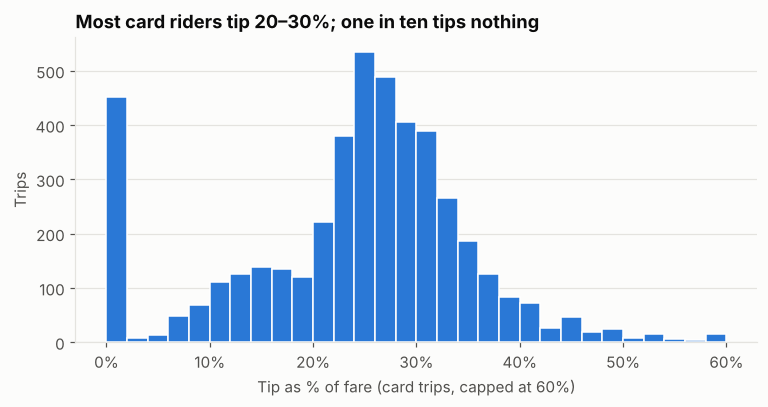

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(card.tip_pct.clip(upper=60), bins=np.arange(0, 62, 2), color=BLUE, edgecolor="white", linewidth=1)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set(xlabel="Tip as % of fare (card trips, capped at 60%)", ylabel="Trips")
ax.grid(axis="x", visible=False)
ax.set_title("Most card riders tip 20–30%; one in ten tips nothing")
save(fig, "06_tip_distribution");

In [15]:
by_borough = (card.groupby("pickup_borough")
                  .agg(trips=("tip_pct", "size"), median_tip_pct=("tip_pct", "median"),
                       share_no_tip=("tip", lambda s: (s == 0).mean()))
                  .sort_values("median_tip_pct"))
by_color = card.groupby("color").agg(trips=("tip_pct", "size"), median_tip_pct=("tip_pct", "median"),
                                     share_no_tip=("tip", lambda s: (s == 0).mean()))
display(by_borough, by_color)

,trips,median_tip_pct,share_no_tip
pickup_borough,,,
Bronx,72,0.00,0.93
Brooklyn,256,0.00,0.50
Queens,373,21.18,0.20
Manhattan,3826,26.57,0.04


,trips,median_tip_pct,share_no_tip
color,,,
green,561,11.76,0.46
yellow,3977,26.33,0.05


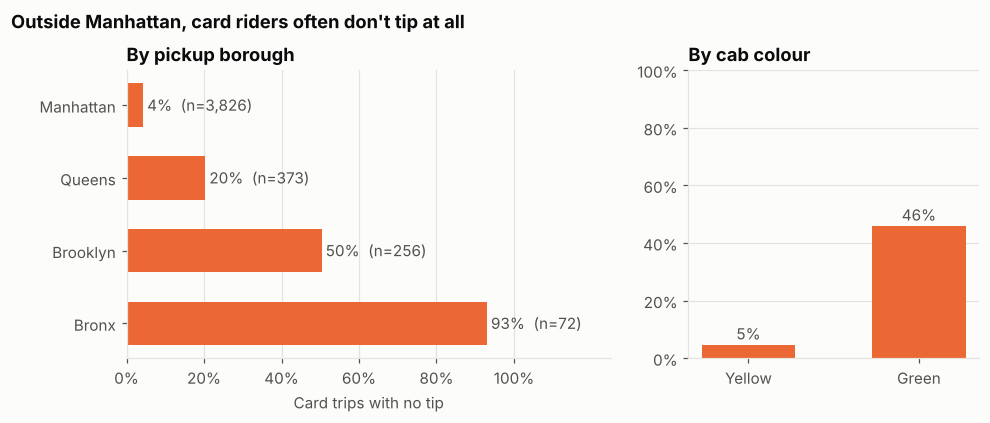

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [2, 1.2]})
ax = axes[0]
ax.barh(by_borough.index, by_borough.share_no_tip * 100, color=ORANGE, height=0.6)
for y, (v, n) in enumerate(zip(by_borough.share_no_tip, by_borough.trips)):
    ax.text(v * 100 + 1, y, f"{v:.0%}  (n={n:,})", va="center", color=TEXT_SECONDARY)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set(xlabel="Card trips with no tip", xlim=(0, 125), xticks=range(0, 101, 20))
ax.grid(axis="y", visible=False)
ax.set_title("By pickup borough")

ax = axes[1]
ax.bar(["Yellow", "Green"], by_color.loc[["yellow", "green"], "share_no_tip"] * 100,
       color=ORANGE, width=0.55)
for x, v in enumerate(by_color.loc[["yellow", "green"], "share_no_tip"]):
    ax.text(x, v * 100 + 2, f"{v:.0%}", ha="center", color=TEXT_SECONDARY)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set(ylim=(0, 100))
ax.grid(axis="x", visible=False)
ax.set_title("By cab colour")
fig.suptitle("Outside Manhattan, card riders often don't tip at all", x=0.02, ha="left",
             fontweight="bold", fontsize=12, y=1.04)
save(fig, "07_no_tip_share");

In [17]:
yellow, green = (card.loc[card.color == c, "tip_pct"] for c in ["yellow", "green"])
u = stats.mannwhitneyu(yellow, green, alternative="two-sided")
print(f"Mann–Whitney U, yellow vs green tip %: U = {u.statistic:,.0f}, p = {u.pvalue:.1e}")

# Is it the cab or the borough? Compare within Manhattan only.
man = card[card.pickup_borough == "Manhattan"]
print(man.groupby("color").agg(trips=("tip_pct", "size"), median_tip_pct=("tip_pct", "median"),
                                share_no_tip=("tip", lambda s: (s == 0).mean())))

Mann–Whitney U, yellow vs green tip %: U = 1,708,487, p = 1.1e-92
        trips  median_tip_pct  share_no_tip
color                                      
green     154           22.29          0.19
yellow   3672           26.67          0.04


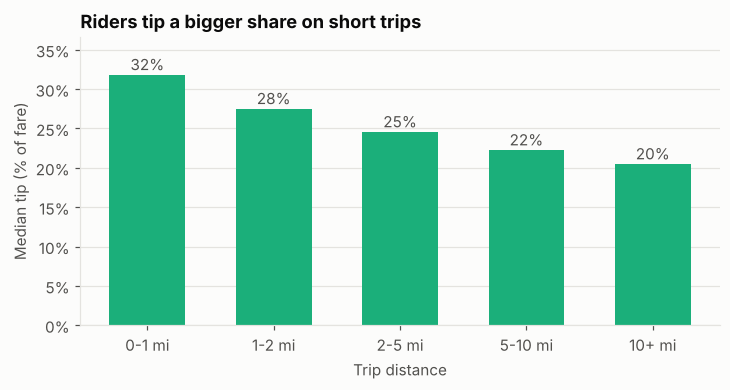

In [18]:
tip_dist = card.groupby("distance_band", observed=True)["tip_pct"].median()
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(tip_dist.index.astype(str), tip_dist.values, color=AQUA, width=0.6)
for x, v in enumerate(tip_dist.values):
    ax.text(x, v + 0.6, f"{v:.0f}%", ha="center", color=TEXT_SECONDARY)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set(xlabel="Trip distance", ylabel="Median tip (% of fare)", ylim=(0, tip_dist.max() * 1.15))
ax.grid(axis="x", visible=False)
ax.set_title("Riders tip a bigger share on short trips")
save(fig, "08_tip_by_distance");

Short trips get a higher *percentage* because riders round up or pick a preset button on the in-cab screen, and a fixed dollar amount is a larger share of a small fare.

## 5. Takeaways

- **Demand** climbs steadily through the day and peaks at 6–7 pm; Friday and Saturday are the busiest days, and weekend nights stay busy past midnight.
- **Traffic** halves taxi speed: the median trip moves at ~9 mph between 8 am and 7 pm versus 15–17 mph before dawn.
- **Fares** are almost entirely explained by distance and time: fare ≈ $2.39 + $2.07/mile + $0.30/minute (test R² 0.97). Short trips cost ~2.5× more per mile because of the flag drop and time spent stopped. The JFK flat fare ($52) shows up as a flat line in the data.
- **Tipping:** cash tips are invisible in the data. Card riders tip a median ~26% of the fare and only 4% of Manhattan card trips leave no tip — versus 50% in Brooklyn and 93% in the Bronx. Green cabs get far fewer tips (46% untipped), and the gap persists even within Manhattan (19% vs 4%), so it isn't only a borough effect.

**Limitations:** a ~6k-trip sample from a single month; cash tips unobserved; tip % is computed on the metered fare, while in-cab screens suggest tips on the total including surcharges, so typical percentages here run a few points high.